In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
import random
from pathlib import Path

from torchvision import transforms

print("PyTorch version:", torch.__version__)

PyTorch version: 2.12.0


In [2]:
import h5py

In [3]:
#REPRODUCIBILITY

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available()
                      else "cpu")

print("Using device:", device)

Using device: mps


In [4]:
path = "/Users/blessing/Desktop/HackBio-internship/AI4Genomics/data/brats2020"
print("Path to dataset files:", path)

Path to dataset files: /Users/blessing/Desktop/HackBio-internship/AI4Genomics/data/brats2020


In [5]:
#get the base directory
ARCHIVE_DIR = '/Users/blessing/Desktop/HackBio-internship/AI4Genomics/data/brats2020/BraTS2020_training_data/content/data/'
FILE_NAMES = os.listdir(ARCHIVE_DIR)

In [6]:
FILE_NAMES

['volume_54_slice_149.h5',
 'volume_95_slice_145.h5',
 'volume_137_slice_59.h5',
 'volume_354_slice_45.h5',
 'volume_190_slice_82.h5',
 'volume_19_slice_43.h5',
 'volume_104_slice_103.h5',
 'volume_238_slice_147.h5',
 'volume_96_slice_102.h5',
 'volume_305_slice_8.h5',
 'volume_107_slice_144.h5',
 'volume_60_slice_80.h5',
 'volume_185_slice_34.h5',
 'volume_151_slice_103.h5',
 'volume_178_slice_128.h5',
 'volume_58_slice_19.h5',
 'volume_308_slice_77.h5',
 'volume_333_slice_1.h5',
 'volume_45_slice_71.h5',
 'volume_286_slice_127.h5',
 'volume_193_slice_148.h5',
 'volume_152_slice_144.h5',
 'volume_321_slice_6.h5',
 'volume_325_slice_58.h5',
 'volume_338_slice_30.h5',
 'volume_213_slice_47.h5',
 'volume_146_slice_44.h5',
 'volume_75_slice_36.h5',
 'volume_353_slice_27.h5',
 'volume_278_slice_50.h5',
 'volume_265_slice_38.h5',
 'volume_146_slice_124.h5',
 'volume_187_slice_128.h5',
 'volume_292_slice_147.h5',
 'volume_248_slice_17.h5',
 'volume_363_slice_60.h5',
 'volume_279_slice_127.h5

In [7]:
len(FILE_NAMES)

57198

In [8]:
RANDOM_SELECT = random.randint(0,len(FILE_NAMES))
print(RANDOM_SELECT)

41905


/Users/blessing/Desktop/HackBio-internship/AI4Genomics/data/brats2020/BraTS2020_training_data/content/data/volume_54_slice_149.h5
<KeysViewHDF5 ['image', 'mask']>
<HDF5 dataset "image": shape (240, 240, 4), type "<f8">
<HDF5 dataset "mask": shape (240, 240, 3), type "|u1">
[[-0.25131582 -0.25131582 -0.25131582 ... -0.25131582 -0.25131582
  -0.25131582]
 [-0.25131582 -0.25131582 -0.25131582 ... -0.25131582 -0.25131582
  -0.25131582]
 [-0.25131582 -0.25131582 -0.25131582 ... -0.25131582 -0.25131582
  -0.25131582]
 ...
 [-0.25131582 -0.25131582 -0.25131582 ... -0.25131582 -0.25131582
  -0.25131582]
 [-0.25131582 -0.25131582 -0.25131582 ... -0.25131582 -0.25131582
  -0.25131582]
 [-0.25131582 -0.25131582 -0.25131582 ... -0.25131582 -0.25131582
  -0.25131582]]


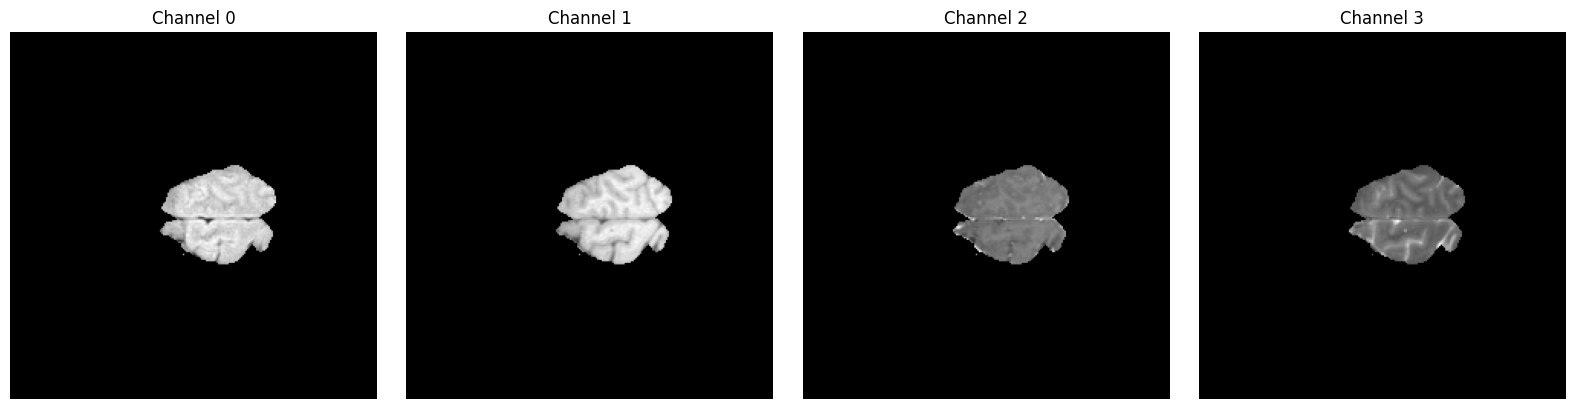

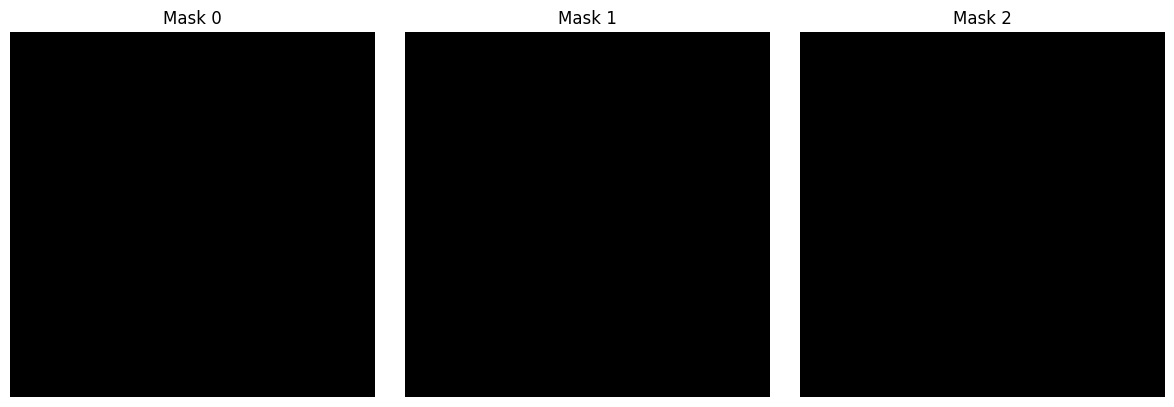

In [9]:
RANDOM_SELECT = random.randint(0,len(FILE_NAMES))

#test file loading
print(ARCHIVE_DIR + FILE_NAMES[0])

TEST_FILE = h5py.File(ARCHIVE_DIR+FILE_NAMES[RANDOM_SELECT], 'r')

print(TEST_FILE.keys())
print(TEST_FILE['image'])
print(TEST_FILE['mask'])

#View test file
img = (TEST_FILE['image'])
mask = (TEST_FILE['mask'])

#
print(img[:, :, 1])

#MODALITIES = ['T1','T1ice', 'T2', 'FLAIR']
MODALITIES = [0,1,2,3]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for i in range(4):
    axes[i].imshow(img[:, :, i], cmap='gray')
    axes[i].set_title(f'Channel {MODALITIES[i]}')
    axes[i].axis('off')
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i in range(3):
    axes[i].imshow(mask[:, :, i], cmap='gray')
    axes[i].set_title(f'Mask {i}')
    axes[i].axis('off')
plt.tight_layout()
plt.show()

In [10]:
class BratsSegmentationDataset(Dataset):
    def __init__(self, img_size = (240,240), cache_file="valid_files.txt"):
        self.img_size = img_size
        cache = Path(cache_file)

        # scanning all 57k files is slow, so reuse the list from a previous run
        if cache.exists():
            self.files = cache.read_text().splitlines()
            print(f"Valid non-empty samples: {len(self.files)} (loaded from {cache})")
            return

        self.files = []
        for file in FILE_NAMES:
            if not file.endswith('.h5'):
                continue

            file_path = ARCHIVE_DIR + file

            with h5py.File(file_path, "r") as f:
                # .shape only reads metadata, not the pixel data
                if f["image"].shape != (240, 240, 4):
                    continue
                if f["mask"].shape != (240, 240, 3):
                    continue
                #clean up masks: skip slices with no tumor
                if not f["mask"][:].any():
                    continue

            #append only clean files with a mask
            self.files.append(file_path)

        cache.write_text("\n".join(self.files))
        print(f"Valid non-empty samples: {len(self.files)}")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        Image_path = self.files[idx]
        #print(Image_path)
        with h5py.File(Image_path, 'r') as IMG_FILE:
            img = IMG_FILE['image'][:, :, 3]
            mask = IMG_FILE['mask'][:]
        #print(mask)

        #return only FLAIR
        img = torch.tensor(img, dtype=torch.float32).unsqueeze(0)
        img = (img - img.min()) / (img.max() - img.min() + 1e-8) #normalize
        tumor_mask = (mask.sum(axis=2) > 0).astype(np.float32)
        mask = torch.tensor(tumor_mask, dtype=torch.float32).unsqueeze(0)
    
        return {
            'image': img,
            'mask': mask
        }

Valid non-empty samples: 24422
Using 3000 samples
torch.Size([1, 240, 240]) torch.float32
torch.Size([1, 240, 240]) 0.0 1.0


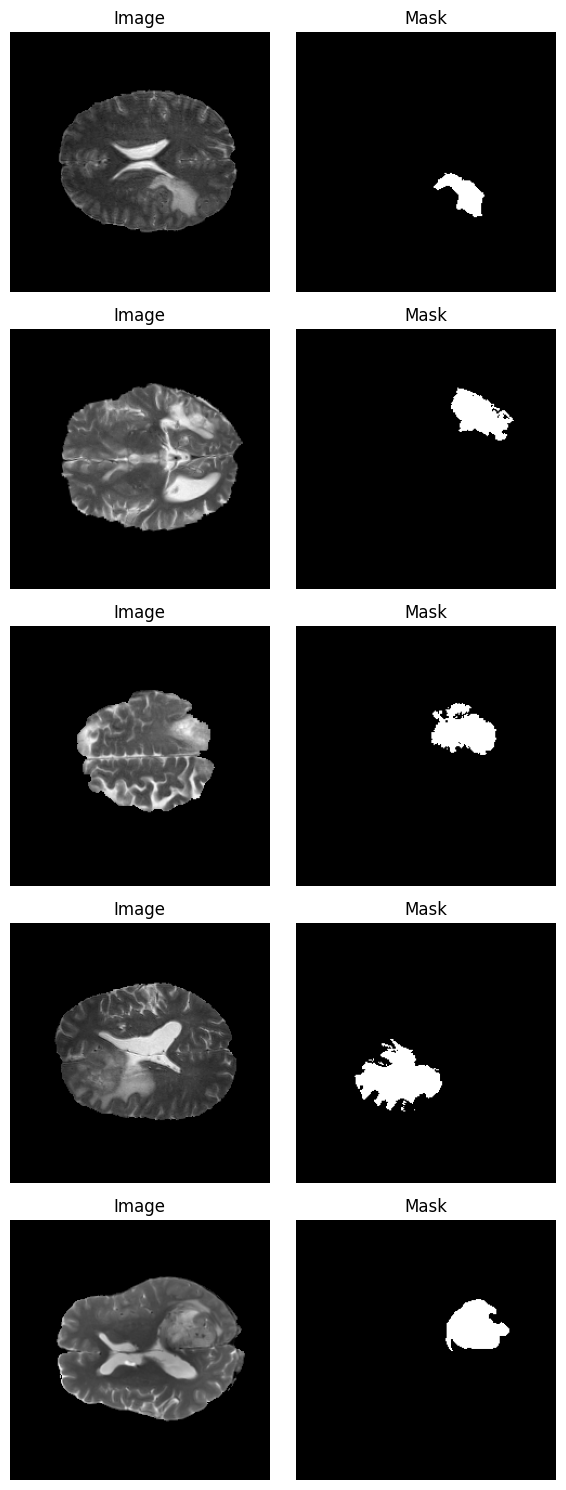

In [11]:
full_dataset = BratsSegmentationDataset()

# train on a random subset so an epoch finishes in reasonable time.
# set N_SAMPLES = None to use every slice.
N_SAMPLES = 3000
if N_SAMPLES is not None and N_SAMPLES < len(full_dataset.files):
    full_dataset.files = random.Random(42).sample(full_dataset.files, N_SAMPLES)
print(f"Using {len(full_dataset)} samples")

sample = full_dataset[0]
print(sample['image'].shape, sample['image'].dtype)
print(sample['mask'].shape, sample['mask'].min().item(), sample['mask'].max().item())

total_size = len(full_dataset)
train_size = int(0.85 * total_size)
val_size = total_size - train_size

train_dataset, val_dataset = random_split(
    full_dataset, [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False)

# Visualize 5 pairs
fig, axes = plt.subplots(5, 2, figsize=(6, 15))
for i in range(5):
    sample = full_dataset[i]
    axes[i,0].imshow(sample['image'][0], cmap='gray')
    axes[i,0].set_title('Image'); axes[i,0].axis('off')
    axes[i,1].imshow(sample['mask'][0], cmap='gray')
    axes[i,1].set_title('Mask'); axes[i,1].axis('off')
plt.tight_layout()
plt.show()

## Task 2: Build the U-Net Architecture

We build a full U-Net with:
- **Encoder path** — repeated `DoubleConv` + downsampling (`MaxPool2d`) blocks that shrink spatial size while growing channel depth.
- **Bottleneck** — the deepest `DoubleConv` (512 channels) connecting encoder and decoder.
- **Decoder path** — `ConvTranspose2d` upsampling that restores spatial resolution.
- **Skip connections** — encoder feature maps are concatenated onto the matching decoder stage so fine spatial detail is preserved.
- **Final segmentation layer** — a `1x1` conv mapping to `out_channel=1` (single tumor / background logit per pixel).

Channel widths are half of the original U-Net (32 → 512 instead of 64 → 1024) so it trains in reasonable time without a large GPU.

In [12]:
# --- U-Net building blocks ---

class DoubleConv(nn.Module):
    """(conv -> BN -> ReLU) x 2"""
    def __init__(self, in_channel, out_channel):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channel, out_channel, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channel),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channel, out_channel, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channel),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class Down(nn.Module):
    """Downsample with maxpool then DoubleConv (encoder step)."""
    def __init__(self, in_channel, out_channel):
        super().__init__()
        self.down = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(in_channel, out_channel),
        )

    def forward(self, x):
        return self.down(x)


class Up(nn.Module):
    """Upsample, concatenate the encoder skip connection, then DoubleConv (decoder step)."""
    def __init__(self, in_channel, out_channel):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channel, in_channel // 2, kernel_size=2, stride=2)
        self.conv = DoubleConv(in_channel, out_channel)

    def forward(self, x_decoder, x_encoder):
        x_decoder = self.up(x_decoder)

        # pad in case odd sizes made the decoder map slightly smaller than the skip map
        diff_y = x_encoder.size(2) - x_decoder.size(2)
        diff_x = x_encoder.size(3) - x_decoder.size(3)
        x_decoder = F.pad(x_decoder, [diff_x // 2, diff_x - diff_x // 2,
                                      diff_y // 2, diff_y - diff_y // 2])

        # skip connection: concatenate encoder features onto decoder features
        x = torch.cat([x_encoder, x_decoder], dim=1)
        return self.conv(x)

In [13]:
# --- Full U-Net ---

class UNet(nn.Module):
    def __init__(self, in_channel=1, out_channel=1):
        super().__init__()

        # encoder path
        self.inc = DoubleConv(in_channel, 32)
        self.down1 = Down(32, 64)
        self.down2 = Down(64, 128)
        self.down3 = Down(128, 256)

        # bottleneck
        self.down4 = Down(256, 512)

        # decoder path (with skip connections)
        self.up1 = Up(512, 256)
        self.up2 = Up(256, 128)
        self.up3 = Up(128, 64)
        self.up4 = Up(64, 32)

        # final segmentation layer
        self.outc = nn.Conv2d(32, out_channel, kernel_size=1)

    def forward(self, x):
        x1 = self.inc(x)     # skip 1
        x2 = self.down1(x1)  # skip 2
        x3 = self.down2(x2)  # skip 3
        x4 = self.down3(x3)  # skip 4
        x5 = self.down4(x4)  # bottleneck

        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)
        logits = self.outc(x)
        return logits

In [14]:
model = UNet(in_channel=1, out_channel=1).to(device)

# print the architecture
print(model)

# parameter count
n_params = sum(p.numel() for p in model.parameters())
print(f"\nTotal parameters: {n_params:,}")

# verify the output dimensions match the target mask dimensions
batch = next(iter(train_loader))
out = model(batch["image"].to(device))
print("\nInput  shape:", batch["image"].shape)
print("Output shape:", out.shape)
print("Mask   shape:", batch["mask"].shape)
assert out.shape == batch["mask"].shape, "Output shape must match mask shape!"
print("\nOutput dimensions match the target mask dimensions.")

UNet(
  (inc): DoubleConv(
    (block): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (down1): Down(
    (down): Sequential(
      (0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (1): DoubleConv(
        (block): Sequential(
          (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU(inplace=True)
          (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (4): BatchNorm2d(64, eps=1e-05

## Task 3: Train the Model

We train with **`BCEWithLogitsLoss`** (binary cross entropy on the raw logits) and the **Adam** optimizer.
During each epoch we track loss plus the two overlap metrics (Dice and IoU) on both the training and validation sets, then plot the loss curves.

### Dice and IoU metrics

Both measure the overlap between the predicted mask and the ground truth, ranging from 0 (no overlap) to 1 (perfect overlap):

$$\text{Dice} = \frac{2 \times |P \cap G|}{|P| + |G|} \qquad\qquad \text{IoU} = \frac{|P \cap G|}{|P \cup G|}$$

We threshold the sigmoid probabilities at 0.5 to get a hard binary prediction before computing them.

In [15]:
# --- Overlap metrics (computed per-image, then averaged over the batch) ---

def dice_coefficient_from_logits(logits, targets, threshold=0.5, eps=1e-7):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()

    intersection = (preds * targets).sum(dim=(1, 2, 3))
    union = preds.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))

    dice = (2 * intersection + eps) / (union + eps)
    return dice.mean().item()


def iou_from_logits(logits, targets, threshold=0.5, eps=1e-7):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()

    intersection = (preds * targets).sum(dim=(1, 2, 3))
    total = preds.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))
    union = total - intersection

    iou = (intersection + eps) / (union + eps)
    return iou.mean().item()

In [16]:
# --- Training / evaluation loops ---

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = running_dice = running_iou = 0.0
    n_batches = 0

    for batch in loader:
        images = batch["image"].to(device)
        masks = batch["mask"].to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, masks)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        running_loss += loss.item()
        running_dice += dice_coefficient_from_logits(logits, masks)
        running_iou += iou_from_logits(logits, masks)
        n_batches += 1

        # progress, so a long epoch doesn't look frozen
        if n_batches % 20 == 0:
            print(f"  batch {n_batches}/{len(loader)} | loss {loss.item():.4f}", flush=True)

    return {
        "loss": running_loss / n_batches,
        "dice": running_dice / n_batches,
        "iou": running_iou / n_batches,
    }


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = running_dice = running_iou = 0.0
    n_batches = 0

    for batch in loader:
        images = batch["image"].to(device)
        masks = batch["mask"].to(device)

        logits = model(images)
        loss = criterion(logits, masks)

        running_loss += loss.item()
        running_dice += dice_coefficient_from_logits(logits, masks)
        running_iou += iou_from_logits(logits, masks)
        n_batches += 1

    return {
        "loss": running_loss / n_batches,
        "dice": running_dice / n_batches,
        "iou": running_iou / n_batches,
    }

In [17]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [18]:
# Training loop.
# Start with a few epochs to check the timing (watch the batch progress lines),
# then raise num_epochs / N_SAMPLES for the final run if there is time.
num_epochs = 5

history = {
    "train_loss": [], "val_loss": [],
    "train_dice": [], "val_dice": [],
    "train_iou":  [], "val_iou":  [],
}

best_val_dice = -1.0
best_state = None

for epoch in range(1, num_epochs + 1):
    train_metrics = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_metrics = evaluate(model, val_loader, criterion, device)

    history["train_loss"].append(train_metrics["loss"])
    history["val_loss"].append(val_metrics["loss"])
    history["train_dice"].append(train_metrics["dice"])
    history["val_dice"].append(val_metrics["dice"])
    history["train_iou"].append(train_metrics["iou"])
    history["val_iou"].append(val_metrics["iou"])

    # keep the best weights by validation Dice
    if val_metrics["dice"] > best_val_dice:
        best_val_dice = val_metrics["dice"]
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    print(
        f"Epoch {epoch:02d} | "
        f"Train loss: {train_metrics['loss']:.4f} | "
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Train Dice: {train_metrics['dice']:.4f} | "
        f"Val Dice: {val_metrics['dice']:.4f} | "
        f"Train IoU: {train_metrics['iou']:.4f} | "
        f"Val IoU: {val_metrics['iou']:.4f}"
    )

# restore the best model for evaluation and visualization
if best_state is not None:
    model.load_state_dict(best_state)
    print(f"\nLoaded best model (Val Dice = {best_val_dice:.4f}).")

  batch 20/319 | loss 0.3996
  batch 40/319 | loss 0.3180
  batch 60/319 | loss 0.2625
  batch 80/319 | loss 0.2191
  batch 100/319 | loss 0.1959
  batch 120/319 | loss 0.1684
  batch 140/319 | loss 0.1355
  batch 160/319 | loss 0.1221
  batch 180/319 | loss 0.1278
  batch 200/319 | loss 0.1037
  batch 220/319 | loss 0.0853
  batch 240/319 | loss 0.0847
  batch 260/319 | loss 0.0857
  batch 280/319 | loss 0.0660
  batch 300/319 | loss 0.0822
Epoch 01 | Train loss: 0.1721 | Val loss: 0.0712 | Train Dice: 0.3627 | Val Dice: 0.4602 | Train IoU: 0.2694 | Val IoU: 0.3571
  batch 20/319 | loss 0.0688
  batch 40/319 | loss 0.0556
  batch 60/319 | loss 0.0508
  batch 80/319 | loss 0.0488
  batch 100/319 | loss 0.0669
  batch 120/319 | loss 0.0378
  batch 140/319 | loss 0.0578
  batch 160/319 | loss 0.0578
  batch 180/319 | loss 0.0424
  batch 200/319 | loss 0.0518
  batch 220/319 | loss 0.0345
  batch 240/319 | loss 0.0312
  batch 260/319 | loss 0.0513
  batch 280/319 | loss 0.0474
  batch 300

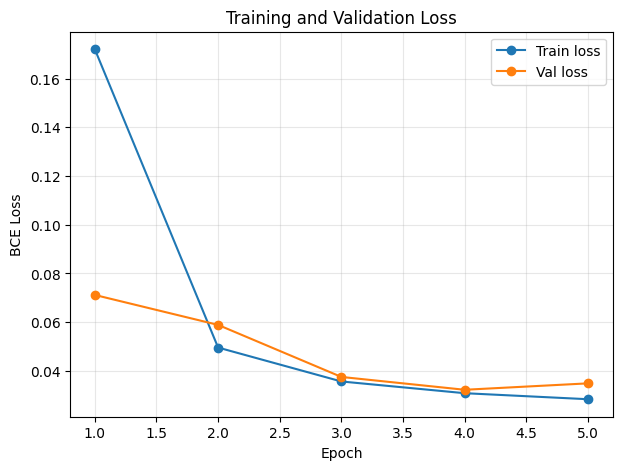

In [19]:
# Plot training and validation loss curves
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(7, 5))
plt.plot(epochs, history["train_loss"], marker="o", label="Train loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Val loss")
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

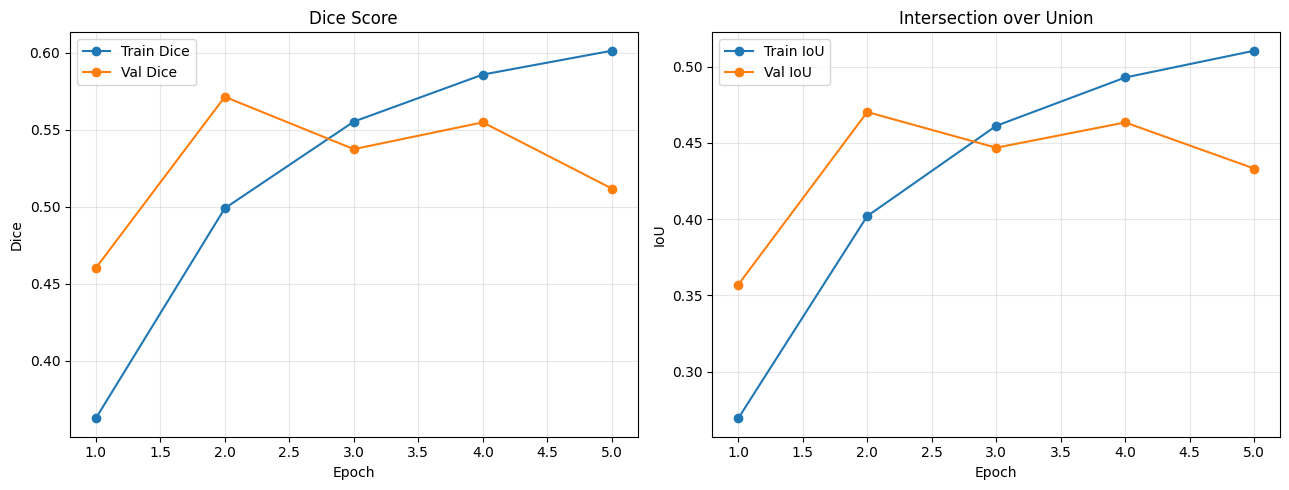

In [20]:
# Plot Dice and IoU over epochs
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(epochs, history["train_dice"], marker="o", label="Train Dice")
axes[0].plot(epochs, history["val_dice"], marker="o", label="Val Dice")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Dice")
axes[0].set_title("Dice Score"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history["train_iou"], marker="o", label="Train IoU")
axes[1].plot(epochs, history["val_iou"], marker="o", label="Val IoU")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("IoU")
axes[1].set_title("Intersection over Union"); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Task 4: Evaluate Performance

We report the final Dice Score and IoU on the validation set using the best model.

In [21]:
final_val = evaluate(model, val_loader, criterion, device)

print("Final validation metrics")
print("-" * 30)
print(f"Loss       : {final_val['loss']:.4f}")
print(f"Dice Score : {final_val['dice']:.4f}")
print(f"IoU        : {final_val['iou']:.4f}")

Final validation metrics
------------------------------
Loss       : 0.0588
Dice Score : 0.5713
IoU        : 0.4703


## Task 5: Visualize Predictions

For 5 validation images we show the original MRI (FLAIR), the ground-truth mask, and the predicted mask side by side.

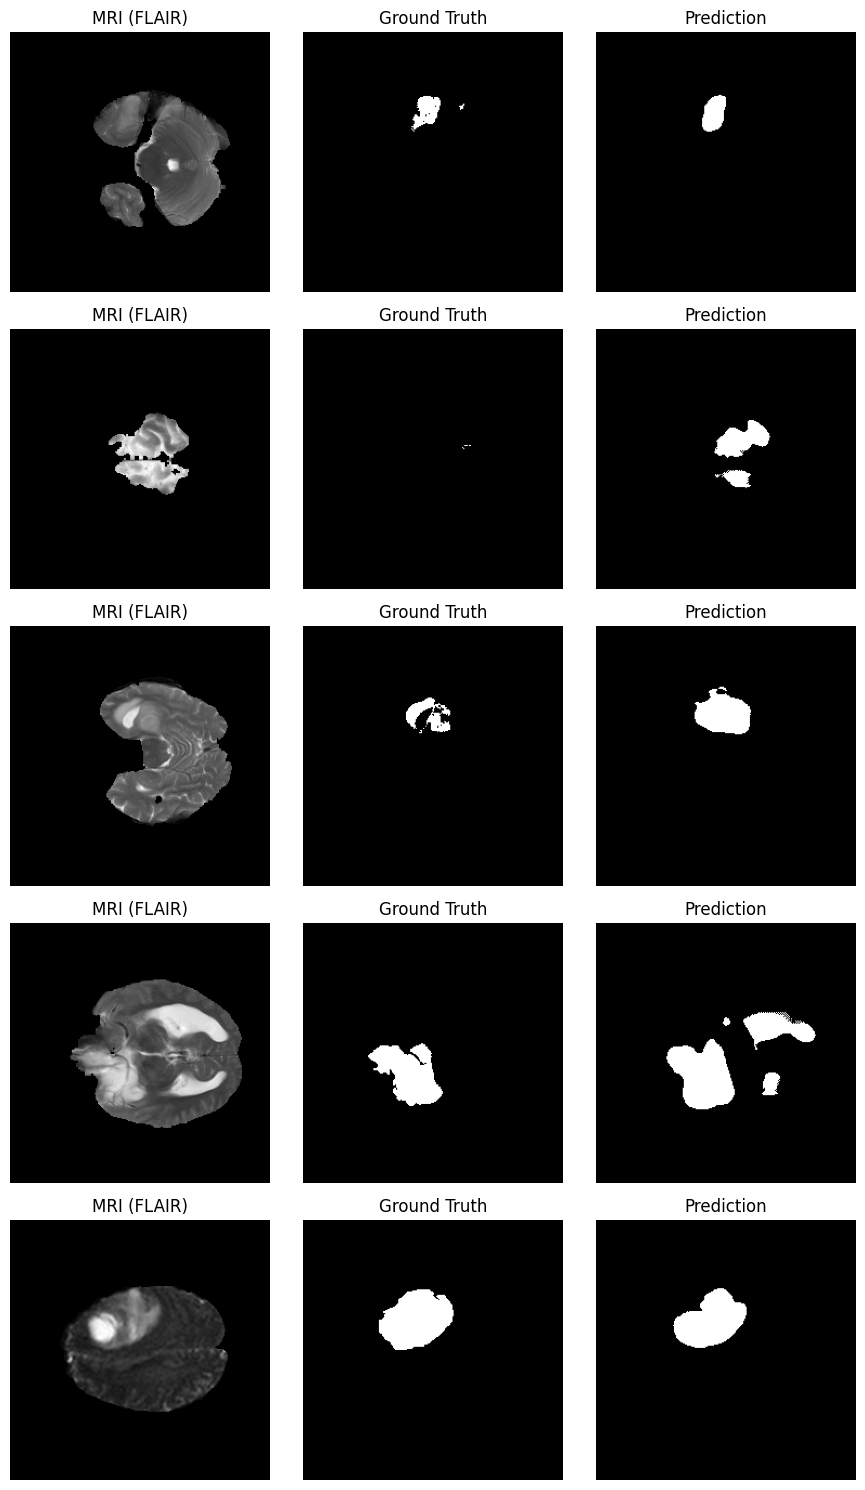

In [22]:
model.eval()
batch = next(iter(val_loader))
with torch.no_grad():
    logits = model(batch["image"].to(device))
    probs = torch.sigmoid(logits)
    preds = (probs > 0.5).float().cpu()

n_show = 5
fig, axes = plt.subplots(n_show, 3, figsize=(9, 3 * n_show))
for i in range(n_show):
    axes[i, 0].imshow(batch["image"][i, 0], cmap="gray")
    axes[i, 0].set_title("MRI (FLAIR)"); axes[i, 0].axis("off")

    axes[i, 1].imshow(batch["mask"][i, 0], cmap="gray")
    axes[i, 1].set_title("Ground Truth"); axes[i, 1].axis("off")

    axes[i, 2].imshow(preds[i, 0], cmap="gray")
    axes[i, 2].set_title("Prediction"); axes[i, 2].axis("off")

plt.tight_layout()
plt.show()

## Results Summary

This notebook implements the full segmentation pipeline for the BraTS2020 dataset:

- **Data loading** — a PyTorch `Dataset`/`DataLoader` that reads the `.h5` slices, keeps the FLAIR modality, normalizes it, builds a binary tumor mask, drops empty slices (24,422 non-empty slices remain), and splits into train/validation sets (85/15).
- **Model** — a complete U-Net (encoder → bottleneck → decoder with skip connections → 1×1 segmentation head, 7.8M parameters) whose output matches the mask dimensions.
- **Training** — `BCEWithLogitsLoss` + Adam (lr = 1e-3), on a random subset of 3,000 slices for 5 epochs on the Apple Silicon GPU (MPS), tracking train/validation loss, Dice, and IoU each epoch and keeping the best model by validation Dice.
- **Evaluation** — final validation Dice Score and IoU.
- **Visualization** — MRI / ground-truth / predicted mask side by side.

### Final validation metrics (best model, epoch 2)

| Metric | Validation |
|--------|-----------|
| Final Dice Score | **0.5713** |
| Final IoU | **0.4703** |
| Validation BCE Loss | 0.0588 |

### Training history

| Epoch | Train loss | Val loss | Train Dice | Val Dice | Train IoU | Val IoU |
|-------|-----------|----------|-----------|----------|-----------|---------|
| 1 | 0.1721 | 0.0712 | 0.3627 | 0.4602 | 0.2694 | 0.3571 |
| 2 | 0.0495 | 0.0588 | 0.4990 | **0.5713** | 0.4021 | **0.4703** |
| 3 | 0.0356 | 0.0375 | 0.5552 | 0.5374 | 0.4612 | 0.4469 |
| 4 | 0.0308 | 0.0322 | 0.5857 | 0.5548 | 0.4929 | 0.4635 |
| 5 | 0.0283 | 0.0348 | 0.6012 | 0.5118 | 0.5105 | 0.4332 |

Training loss falls steadily across all 5 epochs and validation loss mostly follows it, so the model is still learning rather than overfitting. Validation Dice fluctuates between epochs (0.51–0.57) because the validation set is small (450 slices).

The **training/validation loss curves** and the **Dice/IoU curves** are plotted in Task 3, and **sample predictions** are shown in Task 5.

### Limitations and possible improvements

- Only 3,000 of the 24,422 tumor slices and 5 epochs were used, to keep training time manageable; more data and epochs should raise the scores.
- The train/validation split is done per slice, so slices from the same patient volume can appear in both sets; splitting by volume would give a stricter estimate.
- Only the FLAIR channel is used; feeding all 4 MRI modalities, adding a Dice term to the loss (BCE + Dice), and data augmentation are likely to help.